# Phase 1: Classifier (ResNet18)

Classify each scan as **normal**, **benign** or **malignant** by fine-tuning a ResNet18 pretrained on ImageNet.

**Input:** `data/manifest.csv` (created by `00_clean_data.ipynb`)

**Output:** everything is saved to `outputs/classifier/`, ready for the Streamlit app:

| File | What it contains |
| ---- | ---------------- |
| `model.pt` | Trained model weights (best epoch) |
| `config.json` | Classes, image size, normalisation, **malignant threshold** and training settings, needed to rebuild the model and preprocess new images |
| `history.csv` | Loss and accuracy for every epoch |
| `metrics.json` | Test results, with 95% confidence ranges |
| `metrics_v1_vs_v2.csv` | v1 and v2 test results side by side |
| `test_predictions.csv` | Prediction (v1 and v2) and probabilities for every test image |
| `training_curves.png` | Loss and accuracy plots |
| `threshold_tuning.png` | Malignant recall and precision for each threshold (validation set) |
| `confusion_matrix.png` | Test confusion matrices, v1 and v2 |
| `roc_curves.png` | ROC curves for tumour vs normal and malignant vs rest |
| `gradcam_examples.png` | Where the model looks, on sample test images |

**Before the first run:** install torchvision with `.env/bin/pip install torchvision`. The pretrained weights download automatically the first time (about 45 MB).

---

### v2 changes

| Change | Why |
| ------ | --- |
| `TRAIN` setting: `False` reuses the trained v1 model | Fixes that don't need retraining are measured on the **same model**, so any change in the scores comes from the fix, not from training randomness |
| **Malignant threshold tuned on the validation set** | v1 missed 7 of 30 cancers even though the malignant ROC-AUC was 0.95: the model ranked cancers well but was too cautious about calling them malignant |
| **95% confidence ranges** (bootstrap) | The test set has only 30 malignant images, so one image moves recall by 3.3 points |
| v1 and v2 scores shown side by side | To see exactly what each fix changes |

The v1 results are archived in `outputs/archive/v1_baseline/` and git tag `v1-baseline`.

## 1. Imports

In [1]:
import json
import random
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)

## 2. Settings

In [2]:
DATA_DIR = Path('data')
OUTPUT_DIR = Path('outputs/classifier')        # everything the Streamlit app needs is saved here
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ['normal', 'benign', 'malignant']    # class numbers 0, 1, 2
IMAGE_SIZE = 256         # every scan is padded and resized to 256 x 256
BATCH_SIZE = 16
EPOCHS = 30              # maximum; training can stop earlier
LEARNING_RATE = 1e-4     # small, because we fine-tune a pretrained model
PATIENCE = 7             # stop if validation loss hasn't improved for this many epochs
RANDOM_STATE = 42

TRAIN = False                   # v2: False = reuse the saved model.pt, True = train a new model
TARGET_MALIGNANT_RECALL = 0.90  # v2: the malignant threshold is tuned to reach this recall on the validation set
N_BOOTSTRAP = 1000              # v2: resamples used for the 95% confidence ranges

IMAGENET_MEAN = [0.485, 0.456, 0.406]          # the pretrained ResNet expects images normalised this way
IMAGENET_STD = [0.229, 0.224, 0.225]

# Same results every run
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

# Use the Apple GPU (mps) if available, otherwise the CPU
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Using device:', device, '| Train a new model:', TRAIN)

Using device: mps | Train a new model: False


## 3. Load the manifest

In [3]:
df = pd.read_csv(DATA_DIR / 'manifest.csv')
df['target'] = df['label'].map(CLASSES.index)     # class name -> class number

train_df = df[df['split'] == 'train'].reset_index(drop=True)
val_df = df[df['split'] == 'val'].reset_index(drop=True)
test_df = df[df['split'] == 'test'].reset_index(drop=True)

print(f'Train: {len(train_df)}  |  Val: {len(val_df)}  |  Test: {len(test_df)}')

Train: 485  |  Val: 104  |  Test: 104


## 4. Image preprocessing

Every scan goes through the same steps:
1. **Grayscale:** ultrasound has no colour.
2. **Pad to a square, then resize to 256 x 256:** black borders are added instead of stretching, so lesion shapes aren't distorted.
3. **Copy to 3 channels:** the pretrained ResNet expects RGB input.
4. **Normalise** with the ImageNet mean and standard deviation.

Training images also get small **random changes** (augmentation), so the model sees a slightly different version every epoch and overfits less. Vertical flips are never used, because the skin is always at the top of an ultrasound scan.

In [4]:
def pad_to_square(image):
    """Convert to grayscale and fit into IMAGE_SIZE x IMAGE_SIZE with black borders (no stretching)."""
    return ImageOps.pad(image.convert('L'), (IMAGE_SIZE, IMAGE_SIZE), color=0)


# Training: random changes so the model sees a slightly different image every epoch
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),                                              # left-right flip only
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),  # small rotation, shift, zoom
    transforms.ColorJitter(brightness=0.2, contrast=0.2),                           # small brightness/contrast changes
    transforms.Grayscale(num_output_channels=3),                                    # 1 channel -> 3 channels
    transforms.ToTensor(),                                                          # PIL image -> tensor (0 to 1)
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation, test and the app: no random changes
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [5]:
class ScanDataset(Dataset):
    """Gives (image tensor, class number) for each row of the manifest."""

    def __init__(self, frame, transform):
        self.frame = frame
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, i):
        row = self.frame.iloc[i]
        image = pad_to_square(Image.open(DATA_DIR / row['image_path']))
        return self.transform(image), row['target']


train_loader = DataLoader(ScanDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(ScanDataset(val_df, eval_transform), batch_size=BATCH_SIZE)
test_loader = DataLoader(ScanDataset(test_df, eval_transform), batch_size=BATCH_SIZE)   # keeps test_df order

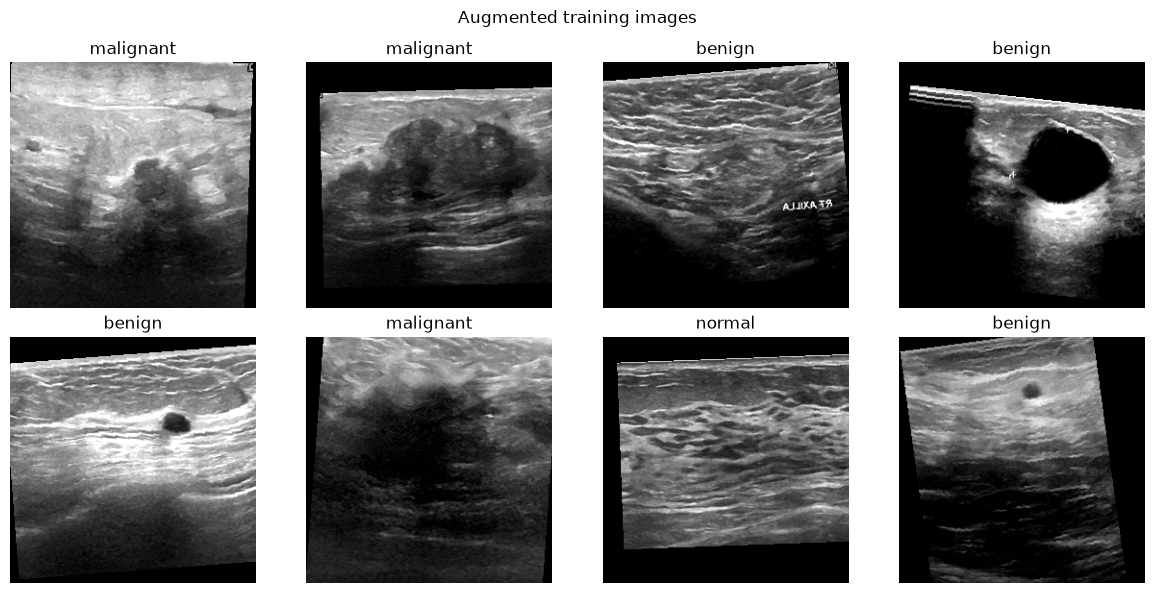

In [6]:
# Look at one batch of augmented training images
images, targets = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, target in zip(axes.flat, images, targets):
    ax.imshow((image[0] * IMAGENET_STD[0] + IMAGENET_MEAN[0]).numpy(), cmap='gray')   # undo normalisation to display
    ax.set_title(CLASSES[target])
    ax.axis('off')
plt.suptitle('Augmented training images')
plt.tight_layout()
plt.show()

## 5. Model, loss and optimizer

We take a ResNet18 already trained on ImageNet and replace its last layer (1000 ImageNet classes) with a new one that has 3 outputs.

Benign images outnumber normal ones by about 3 to 1, so the loss uses **class weights**: mistakes on rarer classes cost more.

In [7]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # pretrained on ImageNet
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))           # new last layer: 512 features -> 3 classes
model = model.to(device)

In [8]:
counts = train_df['target'].value_counts().sort_index()                            # images per class (train)
class_weights = torch.tensor(len(train_df) / (len(CLASSES) * counts.values), dtype=torch.float32)
print('Class weights:', dict(zip(CLASSES, class_weights.numpy().round(2).tolist())))

loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

Class weights: {'normal': 2.069999933242798, 'benign': 0.6100000143051147, 'malignant': 1.1399999856948853}


## 6. Train

After every epoch we check the validation loss. Whenever it reaches a new best, the model is saved to `model.pt`. If it hasn't improved for `PATIENCE` epochs, training stops early (**early stopping**).

**v2:** with `TRAIN = False`, training is skipped and the saved `model.pt` and `history.csv` from the previous run are reused.

In [9]:
def run_epoch(loader, train):
    """One pass over the data. Updates the weights only when train=True. Returns (loss, accuracy)."""
    model.train(train)                                 # train mode or evaluation mode
    total_loss, correct = 0.0, 0

    for images, targets in loader:
        images, targets = images.to(device), targets.to(device)

        with torch.set_grad_enabled(train):            # only track gradients when training
            logits = model(images)
            loss = loss_fn(logits, targets)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * len(targets)
        correct += (logits.argmax(dim=1) == targets).sum().item()

    return total_loss / len(loader.dataset), correct / len(loader.dataset)

In [10]:
if TRAIN:
    history = []
    best_val_loss, best_epoch, epochs_without_improvement = float('inf'), 0, 0

    for epoch in range(1, EPOCHS + 1):
        train_loss, train_acc = run_epoch(train_loader, train=True)
        val_loss, val_acc = run_epoch(val_loader, train=False)
        history.append({'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc,
                        'val_loss': val_loss, 'val_acc': val_acc})
        print(f'Epoch {epoch:2d} | train loss {train_loss:.4f}  acc {train_acc:.3f} '
              f'| val loss {val_loss:.4f}  acc {val_acc:.3f}')

        if val_loss < best_val_loss:                         # new best: save this model
            best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
            torch.save(model.state_dict(), OUTPUT_DIR / 'model.pt')
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print(f'Stopping early: no improvement for {PATIENCE} epochs')
                break

    print(f'Best model: epoch {best_epoch} (val loss {best_val_loss:.4f}), saved to {OUTPUT_DIR}/model.pt')
    history = pd.DataFrame(history)
    history.to_csv(OUTPUT_DIR / 'history.csv', index=False)
else:
    # v2: reuse the previous run's model, history and settings (nothing is retrained)
    previous_config = json.loads((OUTPUT_DIR / 'config.json').read_text())
    history = pd.read_csv(OUTPUT_DIR / 'history.csv')
    best_epoch = previous_config['best_epoch']
    print(f'Skipping training: reusing {OUTPUT_DIR}/model.pt (best epoch {best_epoch}, '
          f"trained on {previous_config['trained_on']})")

Skipping training: reusing outputs/classifier/model.pt (best epoch 5, trained on 2026-11-10 23:03)


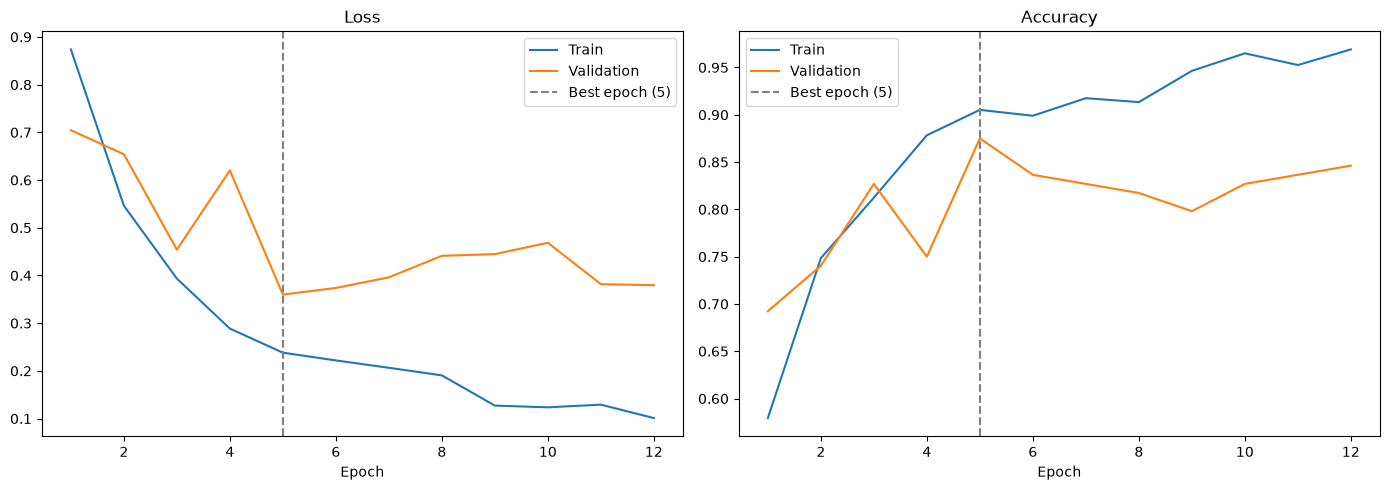

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ['loss', 'acc']):
    ax.plot(history['epoch'], history[f'train_{metric}'], label='Train')
    ax.plot(history['epoch'], history[f'val_{metric}'], label='Validation')
    ax.axvline(best_epoch, color='grey', linestyle='--', label=f'Best epoch ({best_epoch})')
    ax.set_xlabel('Epoch')
    ax.set_title('Loss' if metric == 'loss' else 'Accuracy')
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Evaluate on the test set

We reload the **best** saved model (not the last epoch) and get its probabilities for the validation and test images.

**Two ways to turn probabilities into a class:**

| | Rule | Problem it addresses |
| - | ---- | -------------------- |
| **v1** | Pick the most likely class | Simple, but in v1 it missed 7 of 30 cancers |
| **v2** | Call it **malignant** whenever P(malignant) ≥ a threshold; otherwise pick the more likely of normal and benign | A lower threshold catches more cancers, at the cost of some false alarms |

The threshold is chosen on the **validation set only**, so the test set stays unseen until the final check.

In [12]:
model.load_state_dict(torch.load(OUTPUT_DIR / 'model.pt', map_location=device))
model.eval()


def get_probs(loader):
    """Class probabilities for every image in a loader: one row per image, [P(normal), P(benign), P(malignant)]."""
    all_probs = []
    with torch.no_grad():
        for images, _ in loader:
            all_probs.append(torch.softmax(model(images.to(device)), dim=1).cpu())   # scores -> probabilities
    return torch.cat(all_probs).numpy()


def decide(probs, malignant_threshold=None):
    """Turn probabilities into class numbers.
    v1 (no threshold): the most likely class.
    v2 (threshold): malignant if P(malignant) >= threshold, otherwise the more likely of normal / benign."""
    if malignant_threshold is None:
        return probs.argmax(axis=1)
    return np.where(probs[:, 2] >= malignant_threshold, 2, probs[:, :2].argmax(axis=1))


val_probs = get_probs(val_loader)     # v2: used only to tune the threshold
probs = get_probs(test_loader)        # used only for the final test results
y_val_true = val_df['target'].values
y_true = test_df['target'].values

### v2: tune the malignant threshold on the validation set

For each threshold from 0.05 to 0.50 we measure malignant **recall** (cancers caught) and **precision** (how many "malignant" calls are right) on the validation set. We pick the **highest** threshold that still reaches `TARGET_MALIGNANT_RECALL`: this catches enough cancers with the fewest false alarms.

Chosen malignant threshold: 0.35  (validation recall 0.903, precision 0.700)


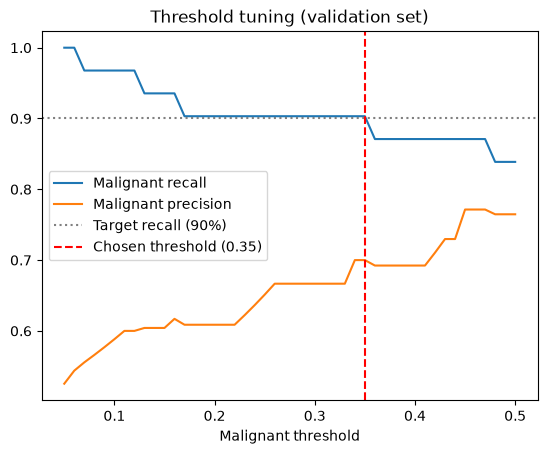

In [13]:
# v2: try thresholds from 0.05 to 0.50 on the validation set
val_is_malignant = y_val_true == 2
rows = []
for threshold in np.round(np.arange(0.05, 0.51, 0.01), 2):
    pred = decide(val_probs, threshold)
    caught = ((pred == 2) & val_is_malignant).sum()
    rows.append({'threshold': threshold,
                 'recall': caught / val_is_malignant.sum(),             # % of cancers caught
                 'precision': caught / max((pred == 2).sum(), 1)})      # % of 'malignant' calls that are right
tuning = pd.DataFrame(rows)

# Highest threshold that still reaches the target recall = the fewest false alarms
meets_target = tuning[tuning['recall'] >= TARGET_MALIGNANT_RECALL]
if len(meets_target):
    MALIGNANT_THRESHOLD = float(meets_target['threshold'].max())
else:
    MALIGNANT_THRESHOLD = float(tuning.loc[tuning['recall'].idxmax(), 'threshold'])
    print(f'Target recall {TARGET_MALIGNANT_RECALL:.0%} not reached on validation: using the threshold with the best recall')

chosen = tuning[tuning['threshold'] == MALIGNANT_THRESHOLD].iloc[0]
print(f"Chosen malignant threshold: {MALIGNANT_THRESHOLD:.2f}  "
      f"(validation recall {chosen['recall']:.3f}, precision {chosen['precision']:.3f})")

plt.plot(tuning['threshold'], tuning['recall'], label='Malignant recall')
plt.plot(tuning['threshold'], tuning['precision'], label='Malignant precision')
plt.axhline(TARGET_MALIGNANT_RECALL, color='grey', linestyle=':', label=f'Target recall ({TARGET_MALIGNANT_RECALL:.0%})')
plt.axvline(MALIGNANT_THRESHOLD, color='red', linestyle='--', label=f'Chosen threshold ({MALIGNANT_THRESHOLD:.2f})')
plt.xlabel('Malignant threshold')
plt.title('Threshold tuning (validation set)')
plt.legend()
plt.savefig(OUTPUT_DIR / 'threshold_tuning.png', dpi=120, bbox_inches='tight')
plt.show()

In [14]:
y_pred_v1 = decide(probs)                              # v1: most likely class
y_pred = decide(probs, MALIGNANT_THRESHOLD)            # v2: tuned malignant threshold

# Save every test prediction (used by the app to show results)
results = test_df[['image_path', 'label', 'has_markers']].copy()
for i, class_name in enumerate(CLASSES):
    results[f'prob_{class_name}'] = probs[:, i].round(4)
results['predicted_v1'] = [CLASSES[i] for i in y_pred_v1]    # v2: keep the v1 prediction for comparison
results['predicted'] = [CLASSES[i] for i in y_pred]
results['correct'] = results['predicted'] == results['label']
results.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)

print('v1: most likely class')
print(classification_report(y_true, y_pred_v1, target_names=CLASSES, digits=3))
print(f'v2: malignant if P(malignant) >= {MALIGNANT_THRESHOLD:.2f}')
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

v1: most likely class
              precision    recall  f1-score   support

      normal      0.750     0.882     0.811        17
      benign      0.862     0.877     0.870        57
   malignant      0.885     0.767     0.821        30

    accuracy                          0.846       104
   macro avg      0.832     0.842     0.834       104
weighted avg      0.850     0.846     0.846       104

v2: malignant if P(malignant) >= 0.35
              precision    recall  f1-score   support

      normal      0.737     0.824     0.778        17
      benign      0.887     0.825     0.855        57
   malignant      0.781     0.833     0.806        30

    accuracy                          0.827       104
   macro avg      0.802     0.827     0.813       104
weighted avg      0.832     0.827     0.828       104



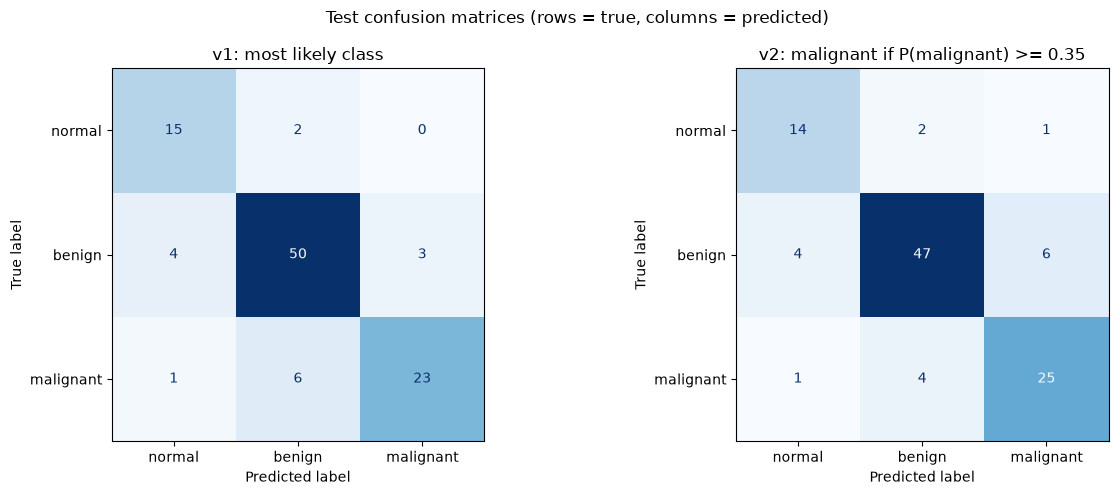

In [15]:
# v2: v1 and v2 confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, pred) in zip(axes, [('v1: most likely class', y_pred_v1),
                                    (f'v2: malignant if P(malignant) >= {MALIGNANT_THRESHOLD:.2f}', y_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred), display_labels=CLASSES).plot(cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(title)

plt.suptitle('Test confusion matrices (rows = true, columns = predicted)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()

### Our two questions

1. **Tumour or not:** P(tumour) = P(benign) + P(malignant), called tumour when it's 0.5 or more.
   - **Sensitivity:** % of tumours found.
   - **Specificity:** % of normal scans correctly called normal.
2. **Malignant or not:** **malignant recall** = % of cancers caught. This is the most important number, because missing a cancer is the worst mistake.

**ROC-AUC** measures how well the probabilities separate the classes, from 0.5 (random guessing) to 1.0 (perfect).

**v2:** the malignant threshold only changes benign vs malignant decisions. Tumour vs normal scores and all ROC-AUCs come from the probabilities, so they are the same in v1 and v2.

In [16]:
# 1. Tumour vs normal, 2. Malignant vs the rest (also used by the ROC plot below)
is_tumour, p_tumour = y_true != 0, probs[:, 1] + probs[:, 2]
is_malignant, p_malignant = y_true == 2, probs[:, 2]


def compute_metrics(y_true, probs, y_pred):
    """All test scores for one set of predicted class numbers."""    # v2: a function, so v1 and v2 use the same code
    is_tumour, p_tumour = y_true != 0, probs[:, 1] + probs[:, 2]
    is_malignant, p_malignant = y_true == 2, probs[:, 2]
    pred_tumour, pred_malignant = p_tumour >= 0.5, y_pred == 2
    return {
        'accuracy': float((y_pred == y_true).mean()),
        'tumour_sensitivity': float((pred_tumour & is_tumour).sum() / max(is_tumour.sum(), 1)),
        'tumour_specificity': float((~pred_tumour & ~is_tumour).sum() / max((~is_tumour).sum(), 1)),
        'tumour_roc_auc': float(roc_auc_score(is_tumour, p_tumour)),
        'malignant_recall': float((pred_malignant & is_malignant).sum() / max(is_malignant.sum(), 1)),
        'malignant_precision': float((pred_malignant & is_malignant).sum() / max(pred_malignant.sum(), 1)),
        'malignant_roc_auc': float(roc_auc_score(is_malignant, p_malignant)),
        'roc_auc_3_class': float(roc_auc_score(y_true, probs, multi_class='ovr', labels=[0, 1, 2])),
    }


metrics_v1 = compute_metrics(y_true, probs, y_pred_v1)
metrics = compute_metrics(y_true, probs, y_pred)          # v2

print(f"{'':22s} {'v1':>7s} {'v2':>7s}")
for name in metrics:
    print(f'{name:22s} {metrics_v1[name]:7.3f} {metrics[name]:7.3f}')

                            v1      v2
accuracy                 0.846   0.827
tumour_sensitivity       0.954   0.954
tumour_specificity       0.824   0.824
tumour_roc_auc           0.975   0.975
malignant_recall         0.767   0.833
malignant_precision      0.885   0.781
malignant_roc_auc        0.950   0.950
roc_auc_3_class          0.950   0.950


### v2: v1 vs v2 with 95% confidence ranges

The test set is small (30 malignant images), so every score has some luck in it. To see how much, we **bootstrap**: draw 1,000 new test sets of the same size by picking test images at random (with replacement), score each one, and keep the middle 95% of the scores.

**How to read it:** if the v1 and v2 ranges overlap a lot, the difference may just be luck. A change that moves the value well outside the other version's range is a real improvement.

In [17]:
def confidence_range(y_true, probs, y_pred, n=N_BOOTSTRAP):
    """95% range of every score: re-draw the test set n times (same size, with replacement) and re-score it."""
    rng = np.random.default_rng(RANDOM_STATE)
    scores = []
    for _ in range(n):
        pick = rng.integers(0, len(y_true), size=len(y_true))     # random test set of the same size
        scores.append(compute_metrics(y_true[pick], probs[pick], y_pred[pick]))
    scores = pd.DataFrame(scores)
    return scores.quantile(0.025), scores.quantile(0.975)


v1_low, v1_high = confidence_range(y_true, probs, y_pred_v1)
v2_low, v2_high = confidence_range(y_true, probs, y_pred)

comparison = pd.DataFrame({
    'v1': [metrics_v1[k] for k in metrics],
    'v1 95% range': [f'{v1_low[k]:.3f} - {v1_high[k]:.3f}' for k in metrics],
    'v2': [metrics[k] for k in metrics],
    'v2 95% range': [f'{v2_low[k]:.3f} - {v2_high[k]:.3f}' for k in metrics],
}, index=list(metrics)).round(3)
comparison.to_csv(OUTPUT_DIR / 'metrics_v1_vs_v2.csv')

metrics['confidence_95'] = {k: [round(float(v2_low[k]), 4), round(float(v2_high[k]), 4)] for k in comparison.index}
comparison

,v1,v1 95% range,v2,v2 95% range
accuracy,0.846,0.769 - 0.913,0.827,0.750 - 0.894
tumour_sensitivity,0.954,0.908 - 1.000,0.954,0.908 - 1.000
tumour_specificity,0.824,0.625 - 1.000,0.824,0.625 - 1.000
tumour_roc_auc,0.975,0.943 - 0.997,0.975,0.943 - 0.997
malignant_recall,0.767,0.615 - 0.903,0.833,0.692 - 0.957
malignant_precision,0.885,0.741 - 1.000,0.781,0.613 - 0.912
malignant_roc_auc,0.950,0.904 - 0.983,0.950,0.904 - 0.983
roc_auc_3_class,0.950,0.917 - 0.976,0.950,0.917 - 0.976


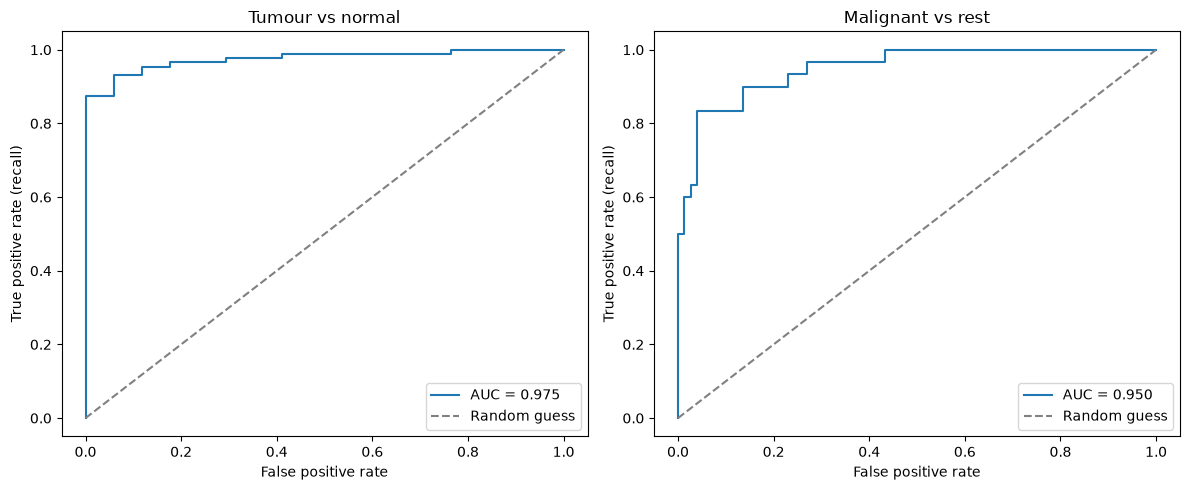

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (title, truth, score, auc) in zip(axes, [
    ('Tumour vs normal', is_tumour, p_tumour, metrics['tumour_roc_auc']),
    ('Malignant vs rest', is_malignant, p_malignant, metrics['malignant_roc_auc']),
]):
    false_pos_rate, true_pos_rate, _ = roc_curve(truth, score)
    ax.plot(false_pos_rate, true_pos_rate, label=f'AUC = {auc:.3f}')
    ax.plot([0, 1], [0, 1], color='grey', linestyle='--', label='Random guess')
    ax.set_xlabel('False positive rate')
    ax.set_ylabel('True positive rate (recall)')
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'roc_curves.png', dpi=120, bbox_inches='tight')
plt.show()

### Shortcut check: images with vs without markers

If accuracy is much higher on images with markers, the model may be using the markers instead of the tissue.

In [19]:
marker_check = results.groupby('has_markers')['correct'].agg(accuracy='mean', images='count')
metrics['accuracy_with_markers'] = float(marker_check['accuracy'].get(True, float('nan')))
metrics['accuracy_without_markers'] = float(marker_check['accuracy'].get(False, float('nan')))
metrics['malignant_threshold'] = MALIGNANT_THRESHOLD     # v2: the decision rule used for these results
metrics['test_images'] = int(len(y_true))

(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2))   # save all test results (v2)
marker_check.round(3)

,accuracy,images
has_markers,,
False,0.923,39
True,0.769,65


## 8. Grad-CAM: where is the model looking?

Grad-CAM colours the parts of the image that pushed the model towards its prediction (red = most important). The **green outline** is the real lesion from the mask. A good model should light up inside or around the green outline, not on markers or empty areas.

In [20]:
def grad_cam(model, image_tensor, class_index):
    """Heatmap (IMAGE_SIZE x IMAGE_SIZE, 0 to 1) of the regions that support class_index."""
    saved = {}
    hook = model.layer4.register_forward_hook(lambda module, inp, out: saved.update(features=out))   # last conv block
    logits = model(image_tensor.unsqueeze(0).to(device))
    hook.remove()

    features = saved['features']                                          # shape (1, 512, 8, 8)
    gradients = torch.autograd.grad(logits[0, class_index], features)[0]  # how each feature affects the score
    weights = gradients.mean(dim=(2, 3), keepdim=True)                    # importance of each of the 512 channels
    cam = F.relu((weights * features).sum(dim=1, keepdim=True))           # weighted sum, keep positive evidence
    cam = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False)
    cam = cam.squeeze().detach().cpu().numpy()
    return cam / (cam.max() + 1e-8)                                       # scale to 0..1


def load_padded_mask(mask_paths):
    """Merge an image's masks and pad/resize them exactly like the image."""
    masks = [np.array(Image.open(DATA_DIR / p).convert('L')) > 127 for p in mask_paths.split(';')]
    merged = Image.fromarray(np.any(masks, axis=0).astype(np.uint8) * 255)
    return np.array(pad_to_square(merged)) > 127

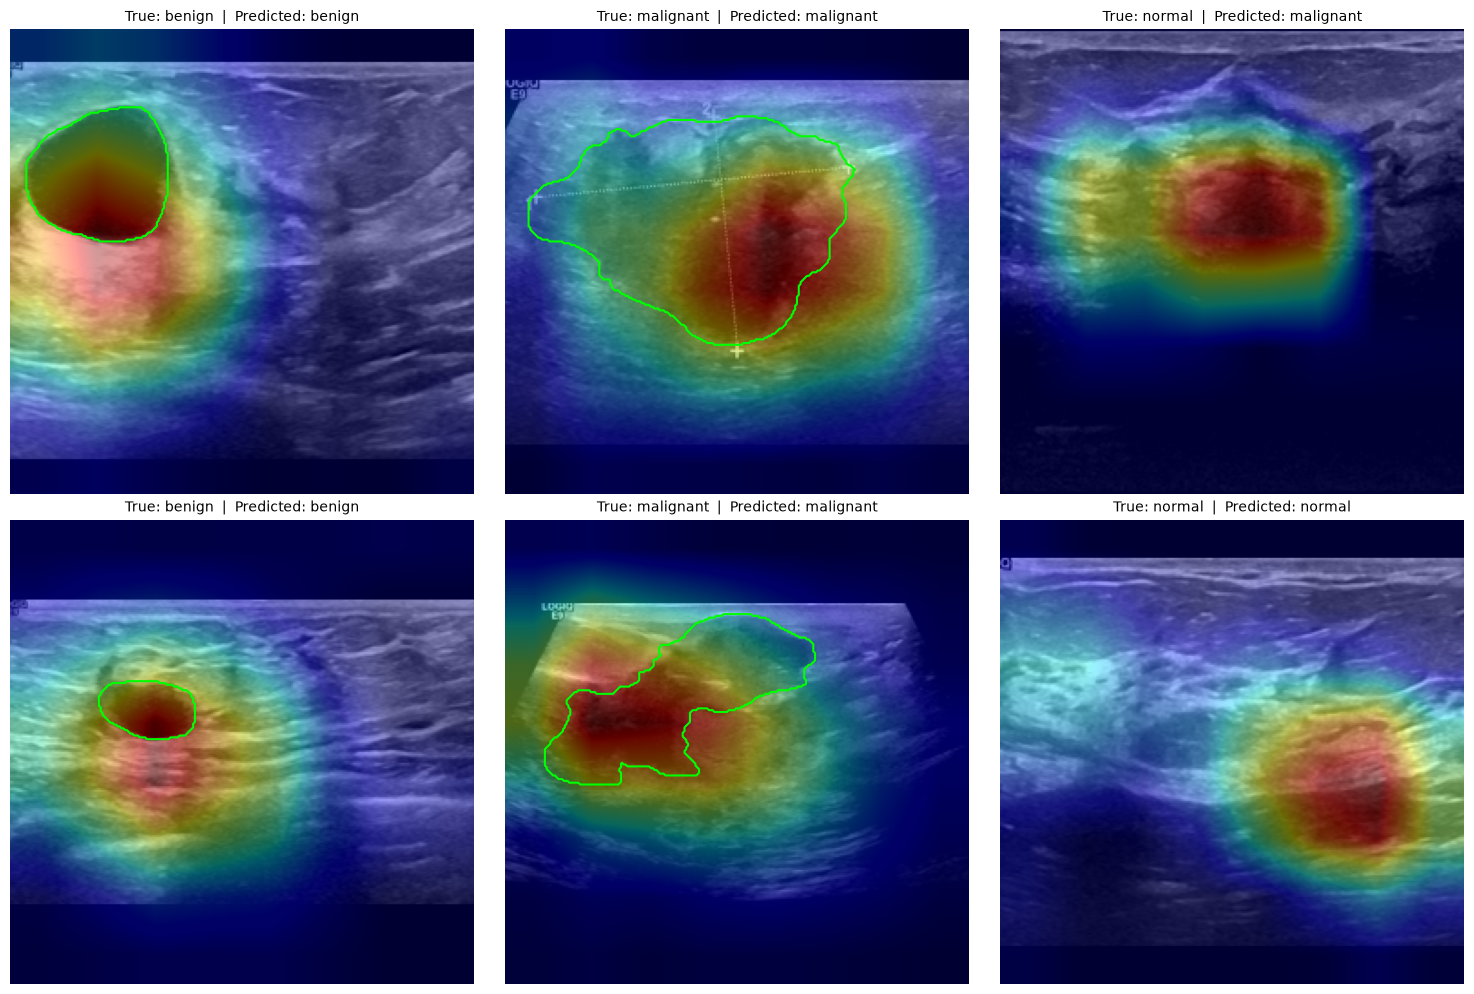

In [21]:
examples = test_df.groupby('label', group_keys=False).sample(2, random_state=RANDOM_STATE)   # 2 per class

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, row in zip(axes.T.flat, examples.itertuples()):
    image = pad_to_square(Image.open(DATA_DIR / row.image_path))
    tensor = eval_transform(image)

    with torch.no_grad():
        image_probs = torch.softmax(model(tensor.unsqueeze(0).to(device)), dim=1).cpu().numpy()
    prediction = int(decide(image_probs, MALIGNANT_THRESHOLD)[0])                 # v2: tuned threshold
    cam = grad_cam(model, tensor, prediction)

    ax.imshow(image, cmap='gray')
    ax.imshow(cam, cmap='jet', alpha=0.4)                                         # Grad-CAM heatmap
    mask = load_padded_mask(row.mask_paths)
    if mask.any():
        ax.contour(mask, levels=[0.5], colors='lime', linewidths=1.5)            # real lesion outline
    ax.set_title(f'True: {row.label}  |  Predicted: {CLASSES[prediction]}', fontsize=10)
    ax.axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'gradcam_examples.png', dpi=120, bbox_inches='tight')
plt.show()

## 9. Save the config

The app needs to rebuild exactly the same model and preprocess uploaded images exactly the same way. Everything it needs is stored here.

In [22]:
config = {
    'model_name': 'ResNet18 classifier',
    'architecture': 'resnet18',
    'classes': CLASSES,
    'image_size': IMAGE_SIZE,
    'preprocessing': 'grayscale -> pad to square with black -> resize -> 3 channels -> ImageNet normalisation',
    'normalize_mean': IMAGENET_MEAN,
    'normalize_std': IMAGENET_STD,
    'malignant_threshold': MALIGNANT_THRESHOLD,                           # v2: tuned on the validation set
    'decision_rule': 'malignant if P(malignant) >= malignant_threshold, else the more likely of normal / benign',
    'gradcam_layer': 'layer4',
    'best_epoch': int(best_epoch),
    'epochs_trained': int(len(history)),
    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,
    'class_weights': class_weights.numpy().round(4).tolist(),
    'images': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
    'trained_on': datetime.now().strftime('%Y-%m-%d %H:%M') if TRAIN else previous_config['trained_on'],   # v2
    'evaluated_on': datetime.now().strftime('%Y-%m-%d %H:%M'),
}

(OUTPUT_DIR / 'config.json').write_text(json.dumps(config, indent=2))
print('Saved files:')
for path in sorted(OUTPUT_DIR.iterdir()):
    print(f'  {path.name:24s} {path.stat().st_size / 1024:8.1f} KB')

Saved files:
  config.json                   0.9 KB
  confusion_matrix.png         42.4 KB
  gradcam_examples.png       1546.9 KB
  history.csv                   0.9 KB
  metrics.json                  0.9 KB
  metrics_v1_vs_v2.csv          0.5 KB
  model.pt                  43733.4 KB
  roc_curves.png               40.2 KB
  test_predictions.csv          8.2 KB
  threshold_tuning.png         34.0 KB
  training_curves.png          80.6 KB


## 10. Check: reload and predict, the way the app will

This rebuilds the model from the saved files alone, without using anything trained above, and predicts one test image. If it works here, the app can use the same two functions.

In [23]:
def load_classifier(folder):
    """Rebuild the trained classifier from model.pt and config.json."""
    config = json.loads((folder / 'config.json').read_text())
    net = models.resnet18(weights=None)                                  # same architecture, no download
    net.fc = nn.Linear(net.fc.in_features, len(config['classes']))
    net.load_state_dict(torch.load(folder / 'model.pt', map_location='cpu'))
    net.eval()
    return net, config


def predict(net, config, image):
    """Class probabilities and predicted class for one PIL image, e.g. an image uploaded in the app."""
    size = config['image_size']
    preprocess = transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        transforms.ToTensor(),
        transforms.Normalize(config['normalize_mean'], config['normalize_std']),
    ])
    tensor = preprocess(ImageOps.pad(image.convert('L'), (size, size), color=0)).unsqueeze(0)
    with torch.no_grad():
        probabilities = torch.softmax(net(tensor), dim=1)[0].numpy()

    # v2: malignant if P(malignant) >= the tuned threshold, otherwise the more likely of normal / benign
    if probabilities[2] >= config['malignant_threshold']:
        predicted = 'malignant'
    else:
        predicted = config['classes'][int(probabilities[:2].argmax())]
    return dict(zip(config['classes'], probabilities.round(4).tolist())), predicted


net, saved_config = load_classifier(OUTPUT_DIR)
sample = test_df.iloc[0]
probabilities, predicted = predict(net, saved_config, Image.open(DATA_DIR / sample['image_path']))
print('Image:         ', sample['image_path'])
print('True label:    ', sample['label'])
print('Probabilities: ', probabilities)
print('Predicted:     ', predicted)

Image:          normal/normal (103).png
True label:     normal
Probabilities:  {'normal': 0.9926000237464905, 'benign': 0.007000000216066837, 'malignant': 0.00039999998989515007}
Predicted:      normal
